# Track Popularity and Explicit Content Analysis

**Objectives:**
1. How is track popularity distributed?
2. How do explicit and non-explicit tracks compare in count and average popularity?
3. How does track popularity vary with duration?
4. How does popularity vary with energy and danceability?

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("spotify-tracks-dataset.csv")

print("Dataset Shape:", df.shape)

display(df.head())

df.info()

Dataset Shape: (114000, 22)


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0.1      114000 non-null  int64  
 1   Unnamed: 0        114000 non-null  int64  
 2   track_id          114000 non-null  object 
 3   artists           113999 non-null  object 
 4   album_name        113999 non-null  object 
 5   track_name        113999 non-null  object 
 6   popularity        114000 non-null  int64  
 7   duration_ms       114000 non-null  int64  
 8   explicit          114000 non-null  bool   
 9   danceability      114000 non-null  float64
 10  energy            114000 non-null  float64
 11  key               114000 non-null  int64  
 12  loudness          114000 non-null  float64
 13  mode              114000 non-null  int64  
 14  speechiness       114000 non-null  float64
 15  acousticness      114000 non-null  float64
 16  instrumentalness  11

In [7]:
req_cols = ['track_name', 'artists', 'popularity', 'explicit', 'duration_ms', 'energy', 'danceability']
df_clean = df[req_cols].copy()

print("Explicit Column Encoding:")
print(df_clean['explicit'].value_counts(dropna=False))

print("\nMissing Values per Column:")
print(df_clean.isnull().sum())

print(f"\nDuplicate Rows: {df_clean.duplicated().sum()}")

Explicit Column Encoding:
explicit
False    104253
True       9747
Name: count, dtype: int64

Missing Values per Column:
track_name      1
artists         1
popularity      0
explicit        0
duration_ms     0
energy          0
danceability    0
dtype: int64

Duplicate Rows: 27268


## 3. Preparing the data

* **Explicit Encoding:** The `explicit` column already uses True/False, so it does not need any formatting changes.
* **Missing Values:** Only one track name and one artist are missing. Since I am analyzing numeric scores like popularity and audio features, I will keep this row so I don't throw away good data.
* **Duplicates:** There are 27,268 duplicate rows in my chosen columns.I will delete these extras so they don't mess up the popularity averages and track counts.

In [8]:
df_clean = df_clean.drop_duplicates()

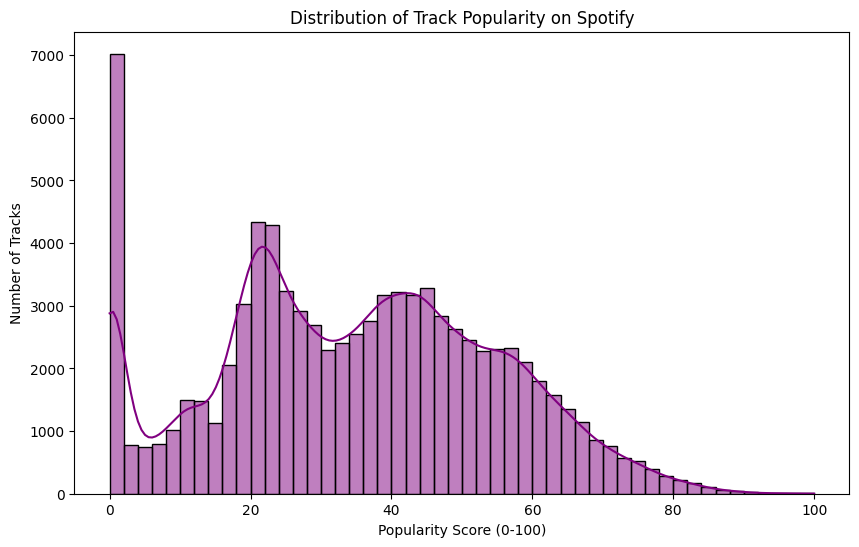

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.histplot(df_clean['popularity'], bins=50, kde=True, color='purple')

plt.title('Distribution of Track Popularity on Spotify')
plt.xlabel('Popularity Score (0-100)')
plt.ylabel('Number of Tracks')

plt.show()

### Observation: Track Popularity Distribution

* **The Zero Popularity Spike:** There is a massive spike of approximately 7000 tracks with a popularity score of exactly 0. This indicates a large volume of tracks in the dataset are either completely undiscovered or have negligible streaming numbers.
* **Two Distinct Peaks:** Excluding the zero scores, the data reveals two main peaks: a sharp peak around a score of 20-25, and a broader one around 40-45.
* **The Rarity of True Hits:** The right tail of the curve drops off steeply after a score of 60. Tracks achieving a popularity score above 80 are extremely rare, highlighting just how difficult it is to make a mainstream "hit."

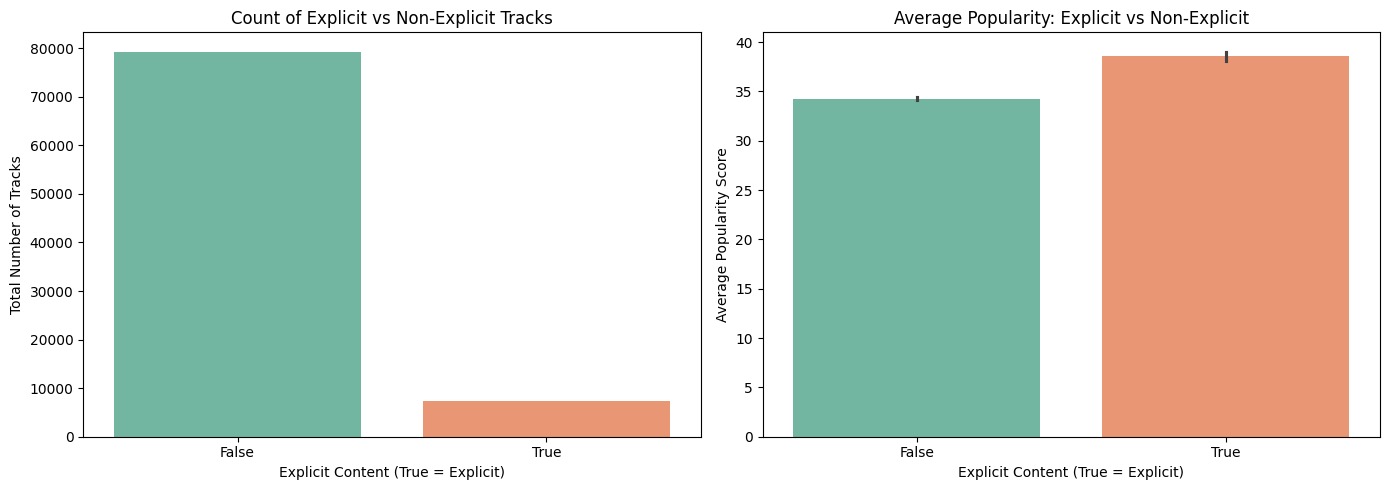

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#Chart 1-Count of tracks
sns.countplot(data=df_clean, x='explicit', hue='explicit', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Count of Explicit vs Non-Explicit Tracks')
axes[0].set_xlabel('Explicit Content (True = Explicit)')
axes[0].set_ylabel('Total Number of Tracks')

#Chart 2-Average popularity
sns.barplot(data=df_clean, x='explicit', y='popularity', hue='explicit', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Average Popularity: Explicit vs Non-Explicit')
axes[1].set_xlabel('Explicit Content (True = Explicit)')
axes[1].set_ylabel('Average Popularity Score')

plt.tight_layout()
plt.show()

### Observation: Explicit vs. Non-Explicit Tracks

* **Volume Imbalance:** The vast majority of tracks on Spotify are non-explicit, with explicit tracks making up only a small fraction of the total dataset.
* **Popularity Advantage:** Despite being significantly fewer in number, explicit tracks maintain a higher average popularity score than non-explicit tracks. This suggests that explicit content does not negatively impact a track's reach and may actually correlate with higher average listener engagement.